In [2]:
#from google.colab import files
#uploaded = files.upload()

In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('04_online_retail.csv')
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,invoice_year,invoice_month,invoice_weekday
0,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010,12,Wednesday
1,536370,10002,INFLATABLE POLITICAL GLOBE,48,2010-12-01 08:45:00,0.85,12583.0,France,2010,12,Wednesday
2,536373,37370,RETRO COFFEE MUGS ASSORTED,6,2010-12-01 09:02:00,1.06,17850.0,United Kingdom,2010,12,Wednesday
3,536381,22771,CLEAR DRAWER KNOB ACRYLIC EDWARDIAN,24,2010-12-01 09:41:00,1.25,15311.0,United Kingdom,2010,12,Wednesday
4,536381,22083,PAPER CHAIN KIT RETROSPOT,1,2010-12-01 09:41:00,2.95,15311.0,United Kingdom,2010,12,Wednesday
...,...,...,...,...,...,...,...,...,...,...,...
24995,581574,21257,VICTORIAN SEWING BOX MEDIUM,2,2011-12-09 12:09:00,7.95,12526.0,Germany,2011,12,Friday
24996,581578,POST,POSTAGE,3,2011-12-09 12:16:00,18.00,12713.0,Germany,2011,12,Friday
24997,581584,85038,6 CHOCOLATE LOVE HEART T-LIGHTS,48,2011-12-09 12:25:00,1.85,13777.0,United Kingdom,2011,12,Friday
24998,581585,84879,ASSORTED COLOUR BIRD ORNAMENT,16,2011-12-09 12:31:00,1.69,15804.0,United Kingdom,2011,12,Friday


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   InvoiceNo        25000 non-null  object 
 1   StockCode        25000 non-null  object 
 2   Description      24935 non-null  object 
 3   Quantity         25000 non-null  int64  
 4   InvoiceDate      25000 non-null  object 
 5   UnitPrice        25000 non-null  float64
 6   CustomerID       18700 non-null  float64
 7   Country          25000 non-null  object 
 8   invoice_year     25000 non-null  int64  
 9   invoice_month    25000 non-null  int64  
 10  invoice_weekday  25000 non-null  object 
dtypes: float64(2), int64(3), object(6)
memory usage: 2.1+ MB


In [6]:
df.head(1)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,invoice_year,invoice_month,invoice_weekday
0,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010,12,Wednesday


In [7]:
df.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,65
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,6300
Country,0
invoice_year,0
invoice_month,0


In [8]:
df['Description'] = df['Description'].fillna('No Description')

In [9]:
df['CustomerID'] = df['CustomerID'].replace('-1','Unknown')

In [10]:
null_unk = df[df['Description']=='No Description']
print(null_unk)

      InvoiceNo StockCode     Description  Quantity          InvoiceDate  \
95       536554     84670  No Description        23  2010-12-01 14:35:00   
305      537012     21535  No Description       -12  2010-12-03 15:39:00   
915      538038     21488  No Description         8  2010-12-09 13:07:00   
986      538129     84497  No Description        79  2010-12-09 15:55:00   
1901     539749     22734  No Description        30  2010-12-21 15:33:00   
...         ...       ...             ...       ...                  ...   
19415    572898     22180  No Description       -15  2011-10-26 14:50:00   
20139    574257     72818  No Description        -3  2011-11-03 13:46:00   
21533    576404     22687  No Description        18  2011-11-15 11:09:00   
22541    577971     22606  No Description         1  2011-11-22 12:12:00   
24420    580743    47591B  No Description         1  2011-12-06 09:30:00   

       UnitPrice  CustomerID         Country  invoice_year  invoice_month  \
95        

In [11]:
df.duplicated().sum()

np.int64(11)

In [12]:
df.shape

(25000, 11)

In [13]:
df = df.drop_duplicates()

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Statistical analyze

In [15]:
df['Quantity'].value_counts()

,count
Quantity,
1,6951
2,3743
12,2851
6,1910
4,1749
...,...
39,1
-73,1
-390,1


In [16]:
df.describe()

,Quantity,UnitPrice,CustomerID,invoice_year,invoice_month
count,24989.000000,24989.000000,18689.000000,24989.000000,24989.000000
mean,9.507903,5.112366,15257.546953,2010.921165,7.556325
std,43.231484,120.092542,1713.560701,0.269486,3.511922
min,-2376.000000,0.000000,12347.000000,2010.000000,1.000000
25%,1.000000,1.250000,13900.000000,2011.000000,5.000000
50%,3.000000,2.080000,15078.000000,2011.000000,8.000000
75%,10.000000,4.130000,16764.000000,2011.000000,11.000000
max,2880.000000,13541.330000,18287.000000,2011.000000,12.000000


In [17]:
df['TotalRevenue'] = df['Quantity'] * df['UnitPrice']

/tmp/ipykernel_2594/1343495195.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['TotalRevenue'] = df['Quantity'] * df['UnitPrice']


In [18]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,invoice_year,invoice_month,invoice_weekday,TotalRevenue
0,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010,12,Wednesday,22.00
1,536370,10002,INFLATABLE POLITICAL GLOBE,48,2010-12-01 08:45:00,0.85,12583.0,France,2010,12,Wednesday,40.80
2,536373,37370,RETRO COFFEE MUGS ASSORTED,6,2010-12-01 09:02:00,1.06,17850.0,United Kingdom,2010,12,Wednesday,6.36
3,536381,22771,CLEAR DRAWER KNOB ACRYLIC EDWARDIAN,24,2010-12-01 09:41:00,1.25,15311.0,United Kingdom,2010,12,Wednesday,30.00
4,536381,22083,PAPER CHAIN KIT RETROSPOT,1,2010-12-01 09:41:00,2.95,15311.0,United Kingdom,2010,12,Wednesday,2.95


In [19]:
total_rows = len(df)
return_rows = (df['Quantity'] < 0).sum()

print(f"Total process count: {total_rows}")
print(f"Return count: {return_rows}")
print(f"Return percentage: {(return_rows / total_rows) * 100}%")

Total process count: 24989
Return count: 492
Return percentage: 1.9688663011725158%


In [20]:
print(df.groupby('invoice_year')['TotalRevenue'].sum())

invoice_year
2010     47538.270
2011    389591.091
Name: TotalRevenue, dtype: float64


In [21]:
print(df.groupby('invoice_month')['TotalRevenue'].sum())

invoice_month
1     27739.070
2     15479.700
3     34376.370
4     22101.950
5     31797.850
6     28593.100
7     31046.721
8     33059.420
9     44791.070
10    54046.310
11    59209.450
12    54888.350
Name: TotalRevenue, dtype: float64


In [22]:
df['Description'].value_counts()

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,114
JUMBO BAG RED RETROSPOT,103
REGENCY CAKESTAND 3 TIER,87
ASSORTED COLOUR BIRD ORNAMENT,77
PARTY BUNTING,68
...,...
BLACK SILOUETTE CANDLE PLATE,1
TRIANGULAR POUFFE VINTAGE,1
N0 SINGING METAL SIGN,1


In [23]:
df['CustomerID'].value_counts()

,count
CustomerID,
17841.0,348
14911.0,299
12748.0,244
14096.0,234
14606.0,119
...,...
12628.0,1
15097.0,1
15969.0,1


In [24]:
df['Country'].value_counts()

,count
Country,
United Kingdom,22763
Germany,486
France,415
EIRE,398
Netherlands,123
Spain,123
Belgium,86
Switzerland,85
Portugal,78


In [25]:
df[df['Country']=='Saudi Arabia']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,invoice_year,invoice_month,invoice_weekday,TotalRevenue
4655,544838,22362,GLASS JAR PEACOCK BATH SALTS,6,2011-02-24 10:34:00,2.95,12565.0,Saudi Arabia,2011,2,Thursday,17.7


# Visualization

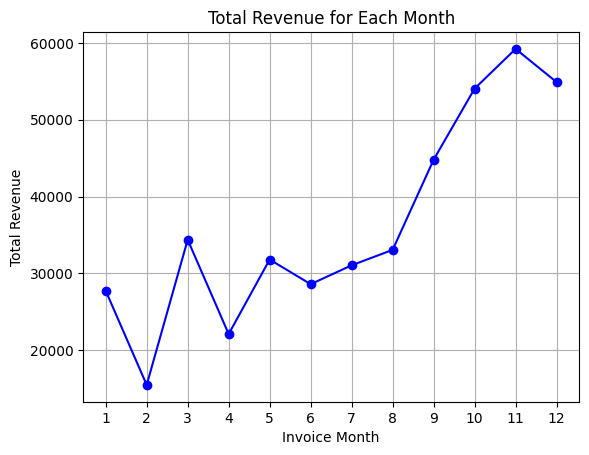

In [26]:
monthly_revenue = df.groupby('invoice_month')['TotalRevenue'].sum()

plt.plot(monthly_revenue.index, monthly_revenue.values, marker='o', color='b', linestyle='-')
plt.xticks(monthly_revenue.index)

plt.title('Total Revenue for Each Month')
plt.xlabel('Invoice Month')
plt.ylabel('Total Revenue')
plt.grid()
plt.show()

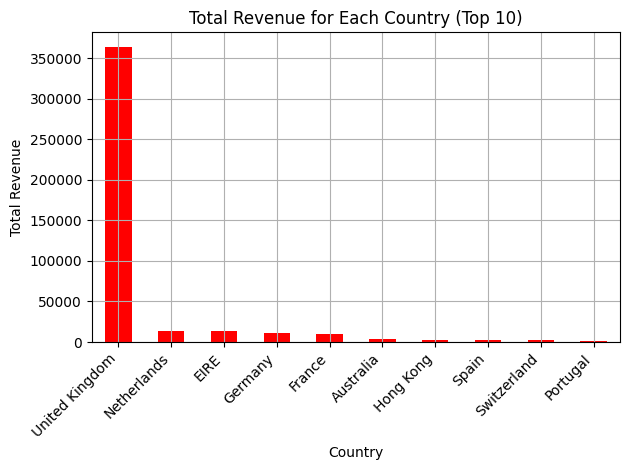

In [27]:
country_revenue = df.groupby('Country')['TotalRevenue'].sum().sort_values(ascending=False).head(10)

country_revenue.plot(kind='bar',color='red')
plt.title('Total Revenue for Each Country (Top 10)')
plt.xlabel('Country')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45, ha='right')
plt.grid()
plt.tight_layout()
plt.show()

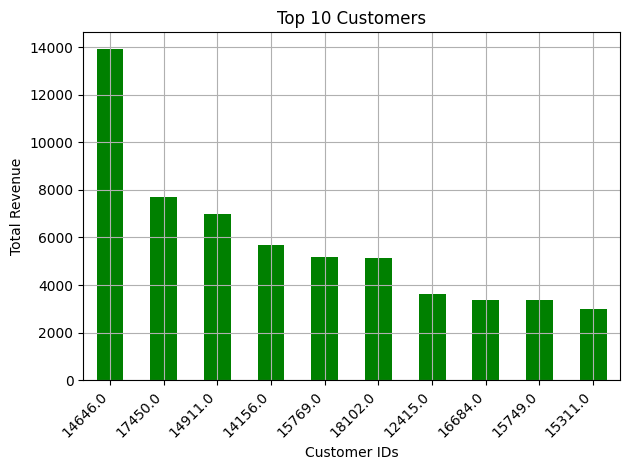

In [28]:
top_customers = df.groupby('CustomerID')['TotalRevenue'].sum().sort_values(ascending=False).head(10)
top_customers.plot(kind='bar',color='green')

plt.title('Top 10 Customers')
plt.xlabel('Customer IDs')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45,ha='right')
plt.grid()
plt.tight_layout()
plt.show()

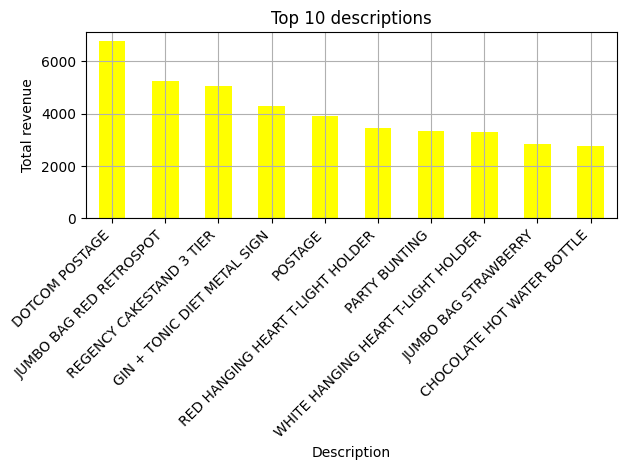

In [29]:
top_sale = df.groupby('Description')['TotalRevenue'].sum().sort_values(ascending=False).head(10)
top_sale.plot(kind='bar',color='yellow')
plt.title('Top 10 descriptions')
plt.xlabel('Description')
plt.ylabel('Total revenue')
plt.xticks(rotation=45,ha='right')
plt.grid()
plt.tight_layout()
plt.show()